# LAB 07 — Bài 11: Positional Encoding

Thí nghiệm theo W7: tạo embedding cho sequence `I love NLP`, cộng sinusoidal positional encoding, đổi thứ tự thành `NLP love I` rồi so sánh representation.

Mục tiêu: quan sát self-attention không tự mã hóa thứ tự; positional information khiến representation phụ thuộc vào vị trí token. Embedding/projection dưới đây là minh họa cố định, chưa được train.

Embedding matrix (d_model=4):


,dim_0,dim_1,dim_2,dim_3
I,0.2,0.1,0.7,0.3
love,0.8,0.4,0.2,0.6
NLP,0.1,0.9,0.5,0.2


Positional encoding for positions 0, 1, 2:


,dim_0,dim_1,dim_2,dim_3
position_0,0.0000,1.0000,0.00,1.0000
position_1,0.8415,0.5403,0.01,1.0000
position_2,0.9093,-0.4161,0.02,0.9998


Input with PE — I love NLP:


,dim_0,dim_1,dim_2,dim_3
I,0.2000,1.1000,0.70,1.3000
love,1.6415,0.9403,0.21,1.6000
NLP,1.0093,0.4839,0.52,1.1998


Input with PE — NLP love I:


,dim_0,dim_1,dim_2,dim_3
NLP,0.1000,1.9000,0.50,1.2000
love,1.6415,0.9403,0.21,1.6000
I,1.1093,-0.3161,0.72,1.2998


Comparison after self-attention and mean pooling:


,Input,L2 distance of mean-pooled representations
0,Without positional encoding,0.0000
1,With positional encoding,0.0095


No PE — summaries equal: True
With PE — summaries differ: True


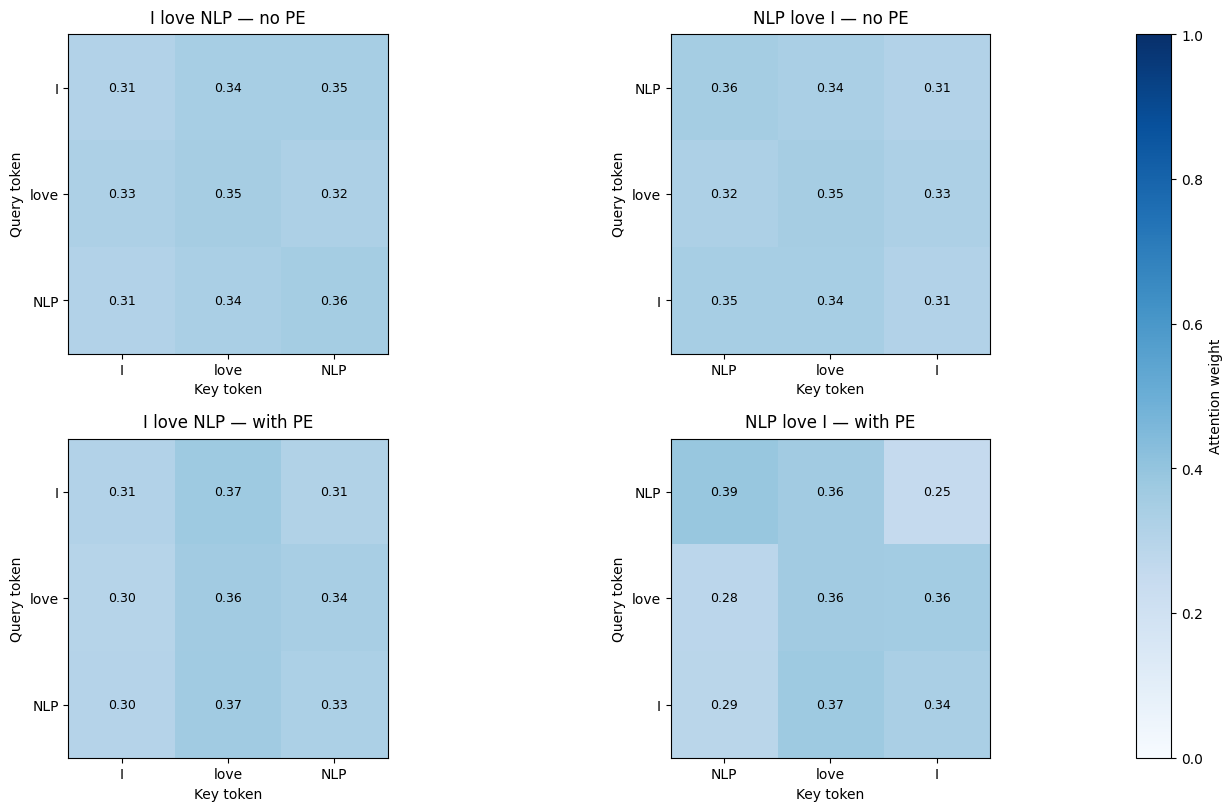

In [ ]:
# Bài 11 — Positional Encoding
# Thí nghiệm: I love NLP vs NLP love I, có/không có positional information.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(11)

# 1. Embedding minh họa cố định: mỗi hàng là một token.
tokens = ["I", "love", "NLP"]
embedding = np.array([
    [0.20, 0.10, 0.70, 0.30],  # I
    [0.80, 0.40, 0.20, 0.60],  # love
    [0.10, 0.90, 0.50, 0.20],  # NLP
], dtype=np.float64)
token_to_embedding = dict(zip(tokens, embedding))
sentence_a = ["I", "love", "NLP"]
sentence_b = ["NLP", "love", "I"]
X_a = np.stack([token_to_embedding[t] for t in sentence_a])
X_b = np.stack([token_to_embedding[t] for t in sentence_b])
d_model = embedding.shape[1]
print("Embedding matrix (d_model=4):")
display(pd.DataFrame(embedding, index=tokens, columns=[f"dim_{i}" for i in range(d_model)]))

# 2. Sinusoidal positional encoding.
def positional_encoding(max_length, d_model):
    pos = np.arange(max_length, dtype=np.float64)[:, None]
    dim = np.arange(d_model, dtype=np.float64)[None, :]
    rate = 1.0 / np.power(10000.0, (2.0 * np.floor(dim / 2.0)) / d_model)
    angle = pos * rate
    return np.where((dim.astype(int) % 2) == 0, np.sin(angle), np.cos(angle))

PE = positional_encoding(len(tokens), d_model)
X_a_pe = X_a + PE
X_b_pe = X_b + PE
print("Positional encoding for positions 0, 1, 2:")
display(pd.DataFrame(PE, index=[f"position_{i}" for i in range(len(tokens))], columns=[f"dim_{i}" for i in range(d_model)]).round(4))
print("Input with PE — I love NLP:")
display(pd.DataFrame(X_a_pe, index=sentence_a, columns=[f"dim_{i}" for i in range(d_model)]).round(4))
print("Input with PE — NLP love I:")
display(pd.DataFrame(X_b_pe, index=sentence_b, columns=[f"dim_{i}" for i in range(d_model)]).round(4))

# 3. Scaled dot-product self-attention với projection cố định, chưa train.
W_Q = rng.normal(0, 0.4, size=(d_model, d_model))
W_K = rng.normal(0, 0.4, size=(d_model, d_model))
W_V = rng.normal(0, 0.4, size=(d_model, d_model))
W_O = rng.normal(0, 0.4, size=(d_model, d_model))
def stable_softmax(scores, axis=-1):
    exps = np.exp(scores - np.max(scores, axis=axis, keepdims=True))
    return exps / np.sum(exps, axis=axis, keepdims=True)
def self_attention(X):
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V
    scores = (Q @ K.T) / np.sqrt(Q.shape[-1])
    weights = stable_softmax(scores, axis=-1)
    return (weights @ V) @ W_O, weights

H_a, A_a = self_attention(X_a)
H_b, A_b = self_attention(X_b)
H_a_pe, A_a_pe = self_attention(X_a_pe)
H_b_pe, A_b_pe = self_attention(X_b_pe)
summary_a, summary_b = H_a.mean(axis=0), H_b.mean(axis=0)
summary_a_pe, summary_b_pe = H_a_pe.mean(axis=0), H_b_pe.mean(axis=0)
comparison = pd.DataFrame([
    ["Without positional encoding", np.linalg.norm(summary_a - summary_b)],
    ["With positional encoding", np.linalg.norm(summary_a_pe - summary_b_pe)],
], columns=["Input", "L2 distance of mean-pooled representations"])
print("Comparison after self-attention and mean pooling:")
display(comparison.round(8))
print("No PE — summaries equal:", np.allclose(summary_a, summary_b, atol=1e-10))
print("With PE — summaries differ:", not np.allclose(summary_a_pe, summary_b_pe, atol=1e-10))

# 4. Heatmaps with a dedicated GridSpec column for the shared colorbar.
fig = plt.figure(figsize=(13, 8), constrained_layout=True)
grid = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.06])
axes = np.array([
    [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])],
    [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])],
])
colorbar_axis = fig.add_subplot(grid[:, 2])
matrices = [A_a, A_b, A_a_pe, A_b_pe]
titles = ["I love NLP — no PE", "NLP love I — no PE",
          "I love NLP — with PE", "NLP love I — with PE"]
labels = [sentence_a, sentence_b, sentence_a, sentence_b]
for ax, matrix, title, words in zip(axes.flat, matrices, titles, labels):
    im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title, pad=8)
    ax.set_xticks(range(len(words)), words)
    ax.set_yticks(range(len(words)), words)
    ax.set_xlabel("Key token")
    ax.set_ylabel("Query token")
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            ax.text(col, row, f"{matrix[row, col]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, cax=colorbar_axis, label="Attention weight")
plt.show()

# Kết luận: không PE, self-attention đổi output theo permutation token,
# nên mean pooling không giữ lại thứ tự. Cộng PE giúp biểu diễn phụ thuộc vị trí.
# Đây là minh họa bằng embedding/projection cố định, không phải mô hình đã train.